In [ ]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import json
import random

RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

# ---------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------
df = pd.read_csv("sonar.csv", header=None)

X = df.iloc[:, :-1].values.astype(float)
y_raw = df.iloc[:, -1].values
y = np.where(y_raw == "M", 1, 0)  # Mine=1, Rock=0

n_features = X.shape[1]
print(f"Loaded Sonar dataset: {X.shape[0]} samples, {n_features} features")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RNG_SEED
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RNG_SEED)

# ---------------------------------------------------------------
# 2. Memoized state evaluator -> SVM 3-fold CV accuracy on TRAIN data
#    (this is the "reward function" evaluator from the paper: sec 4, eq 1)
# ---------------------------------------------------------------
_eval_cache = {}

def state_accuracy(feature_set):
    """feature_set: frozenset of column indices. Returns mean CV accuracy."""
    if len(feature_set) == 0:
        return 0.5  # a coin-flip baseline for the empty feature set
    key = frozenset(feature_set)
    if key in _eval_cache:
        return _eval_cache[key]
    cols = sorted(key)
    clf = SVC(kernel="rbf", C=1.0, gamma="scale")
    acc = cross_val_score(clf, X_train_s[:, cols], y_train, cv=cv, n_jobs=1).mean()
    _eval_cache[key] = acc
    return acc

# ---------------------------------------------------------------
# 3. RL loop: TD(0) + AOR feature scoring
# ---------------------------------------------------------------
ALPHA = 0.3     # learning rate
GAMMA = 0.9     # discount factor
EPSILON = 0.4  # exploration rate in the "seen state" phase
N_EPISODES = 50
MAX_STEPS_PER_EPISODE = 12   # cap trajectory length (full 60 is too slow for a class demo)

V = {}                      # state value table  key: frozenset -> float
visited_states = set()      # states seen before (for random- vs epsilon-greedy phase)
AOR = np.zeros(n_features)  # average-of-reward per feature
select_count = np.zeros(n_features, dtype=int)

episode_max_value = []      # for the "max value-state per episode" plot (paper Fig 1)

feature_pool = list(range(n_features))

for ep in range(N_EPISODES):
    start_feat = random.choice(feature_pool)
    state = frozenset({start_feat})
    select_count[start_feat] += 1
    ep_values = [V.get(state, 0.0)]

    steps = 0
    while len(state) < n_features and steps < MAX_STEPS_PER_EPISODE:
        avail = [f for f in feature_pool if f not in state]
        if not avail:
            break

        # --- action selection: random phase vs epsilon-greedy phase ---
        if state not in visited_states:
            action = random.choice(avail)          # random-based phase (unseen node)
        else:
            if random.random() < EPSILON:
                action = random.choice(avail)       # explore
            else:
                action = max(avail, key=lambda f: AOR[f])  # exploit best AOR so far
        visited_states.add(state)

        next_state = frozenset(state | {action})

        # --- reward: change in SVM accuracy (paper eq. 1) ---
        reward = state_accuracy(next_state) - state_accuracy(state)

        # --- TD(0) update (paper eq. 4) ---
        v_s = V.get(state, 0.0)
        v_s2 = V.get(next_state, 0.0)
        V[state] = v_s + ALPHA * (reward + GAMMA * v_s2 - v_s)

        # --- AOR incremental update (paper eq. 6) ---
        select_count[action] += 1
        k = select_count[action]
        AOR[action] = ((k - 1) * AOR[action] + v_s2) / k

        state = next_state
        ep_values.append(V.get(state, 0.0))
        steps += 1

    episode_max_value.append(max(ep_values))
    if (ep + 1) % 10 == 0:
        print(f"  episode {ep+1}/{N_EPISODES}  max V so far this ep = {max(ep_values):.4f}"
              f"  cached evals = {len(_eval_cache)}")

print("\nRL training done.")
print(f"Total distinct states evaluated: {len(_eval_cache)}")

# Final feature ranking by AOR (this is the RL agent's feature-importance ranking)
rl_ranking = np.argsort(-AOR)  # best first

# ---------------------------------------------------------------
# 4. Wrapper-style final accuracy: best RL feature subset on held-out TEST set
#    (reproduces the paper's "Results of Classification Accuracy" table)
# ---------------------------------------------------------------
best_k, best_acc, best_cols = 1, 0.0, [rl_ranking[0]]
for k in range(1, n_features + 1):
    cols = sorted(rl_ranking[:k])
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
    clf.fit(X_train[:, cols], y_train)
    acc = accuracy_score(y_test, clf.predict(X_test[:, cols]))
    if acc > best_acc:
        best_acc, best_k, best_cols = acc, k, cols

print(f"\nBest RL-selected subset: k={best_k} features, test accuracy={best_acc:.4f}")
print("Selected feature indices:", best_cols)

# ---------------------------------------------------------------
# 5. Filter-method comparison (reproduces paper Fig 3-5 style plot)
# ---------------------------------------------------------------
mm = MinMaxScaler().fit(X_train)
X_train_mm = mm.transform(X_train)

chi2_scores, _ = chi2(X_train_mm, y_train)
f_scores, _ = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=RNG_SEED)
rf = RandomForestClassifier(n_estimators=200, random_state=RNG_SEED).fit(X_train, y_train)
rf_scores = rf.feature_importances_

rankings = {
    "RL (AOR)": rl_ranking,
    "Chi-squared": np.argsort(-chi2_scores),
    "ANOVA F-test": np.argsort(-f_scores),
    "Mutual Info": np.argsort(-mi_scores),
    "Random Forest": np.argsort(-rf_scores),
}

results = {name: [] for name in rankings}
ks = list(range(1, n_features + 1, 2))  # every 2 features to keep it quick
for name, order in rankings.items():
    for k in ks:
        cols = sorted(order[:k])
        clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
        clf.fit(X_train[:, cols], y_train)
        acc = accuracy_score(y_test, clf.predict(X_test[:, cols]))
        results[name].append(acc)

# ---------------------------------------------------------------
# 6. Save everything needed for plotting / the report
# ---------------------------------------------------------------
out = {
    "n_features": n_features,
    "n_samples": int(X.shape[0]),
    "episode_max_value": episode_max_value,
    "aor": AOR.tolist(),
    "rl_ranking": rl_ranking.tolist(),
    "best_k": best_k,
    "best_acc": best_acc,
    "ks": ks,
    "filter_results": results,
}
with open("results.json", "w") as f:
    json.dump(out, f, indent=2)

print("\nSaved results.json")


Loaded Sonar dataset: 208 samples, 60 features
  episode 10/50  max V so far this ep = 0.0000  cached evals = 130
  episode 20/50  max V so far this ep = 0.0000  cached evals = 259
  episode 30/50  max V so far this ep = 0.0000  cached evals = 384
  episode 40/50  max V so far this ep = 0.0000  cached evals = 510
  episode 50/50  max V so far this ep = 0.0288  cached evals = 637

RL training done.
Total distinct states evaluated: 637

Best RL-selected subset: k=44 features, test accuracy=0.8889
Selected feature indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int6

In [ ]:
"""
Replication of: "Feature Selection using Reinforcement Learning"
(Rasoul, Adewole, Akakpo - 2021, arXiv:2101.09460)

Dataset: Statlog (Australian Credit Approval) - 14 features, 690 samples
File format: /content/australian.dat
  - whitespace-separated, NO header row
  - columns 0..12 = features (6 continuous + 8 categorical, already numeric-coded)
  - column 13 (last) = class label, already 0/1
"""

import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import json
import random

RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

# ---------------------------------------------------------------
# 1. Load data  (ONLY SECTION THAT CHANGES vs. the Sonar script)
# ---------------------------------------------------------------
DATA_PATH = "/content/australian.dat"

df = pd.read_csv(DATA_PATH, header=None, sep=r"\s+")
X = df.iloc[:, :-1].values.astype(float)
y = df.iloc[:, -1].values.astype(int)   # already 0/1, no mapping needed

n_features = X.shape[1]
print(f"Loaded Australian dataset: {X.shape[0]} samples, {n_features} features")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RNG_SEED
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RNG_SEED)

# ---------------------------------------------------------------
# 2. Memoized state evaluator -> SVM 3-fold CV accuracy on TRAIN data
# ---------------------------------------------------------------
_eval_cache = {}

def state_accuracy(feature_set):
    if len(feature_set) == 0:
        return 0.5
    key = frozenset(feature_set)
    if key in _eval_cache:
        return _eval_cache[key]
    cols = sorted(key)
    clf = SVC(kernel="rbf", C=1.0, gamma="scale")
    acc = cross_val_score(clf, X_train_s[:, cols], y_train, cv=cv, n_jobs=1).mean()
    _eval_cache[key] = acc
    return acc

# ---------------------------------------------------------------
# 3. RL loop: TD(0) + AOR feature scoring
#    14 features -> the state space is tiny (2^14), so we can afford
#    more episodes and a longer trajectory cap than the Sonar run.
# ---------------------------------------------------------------
ALPHA = 0.3
GAMMA = 0.9
EPSILON = 0.4
N_EPISODES = 120
MAX_STEPS_PER_EPISODE = n_features  # cheap enough to let episodes run to completion

V = {}
visited_states = set()
AOR = np.zeros(n_features)
select_count = np.zeros(n_features, dtype=int)
episode_max_value = []
feature_pool = list(range(n_features))

for ep in range(N_EPISODES):
    start_feat = random.choice(feature_pool)
    state = frozenset({start_feat})
    select_count[start_feat] += 1
    ep_values = [V.get(state, 0.0)]

    steps = 0
    while len(state) < n_features and steps < MAX_STEPS_PER_EPISODE:
        avail = [f for f in feature_pool if f not in state]
        if not avail:
            break

        if state not in visited_states:
            action = random.choice(avail)
        else:
            if random.random() < EPSILON:
                action = random.choice(avail)
            else:
                action = max(avail, key=lambda f: AOR[f])
        visited_states.add(state)

        next_state = frozenset(state | {action})
        reward = state_accuracy(next_state) - state_accuracy(state)

        v_s = V.get(state, 0.0)
        v_s2 = V.get(next_state, 0.0)
        V[state] = v_s + ALPHA * (reward + GAMMA * v_s2 - v_s)

        select_count[action] += 1
        k = select_count[action]
        AOR[action] = ((k - 1) * AOR[action] + v_s2) / k

        state = next_state
        ep_values.append(V.get(state, 0.0))
        steps += 1

    episode_max_value.append(max(ep_values))
    if (ep + 1) % 20 == 0:
        print(f"  episode {ep+1}/{N_EPISODES}  max V so far this ep = {max(ep_values):.4f}"
              f"  cached evals = {len(_eval_cache)}")

print("\nRL training done.")
print(f"Total distinct states evaluated: {len(_eval_cache)}")

rl_ranking = np.argsort(-AOR)

# ---------------------------------------------------------------
# 4. Wrapper-style final accuracy on held-out TEST set
# ---------------------------------------------------------------
best_k, best_acc, best_cols = 1, 0.0, [rl_ranking[0]]
for k in range(1, n_features + 1):
    cols = sorted(rl_ranking[:k])
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
    clf.fit(X_train[:, cols], y_train)
    acc = accuracy_score(y_test, clf.predict(X_test[:, cols]))
    if acc > best_acc:
        best_acc, best_k, best_cols = acc, k, cols

print(f"\nBest RL-selected subset: k={best_k} features, test accuracy={best_acc:.4f}")
print("Selected feature indices:", best_cols)

# ---------------------------------------------------------------
# 5. Filter-method comparison
# ---------------------------------------------------------------
mm = MinMaxScaler().fit(X_train)
X_train_mm = mm.transform(X_train)

chi2_scores, _ = chi2(X_train_mm, y_train)
f_scores, _ = f_classif(X_train, y_train)
mi_scores = mutual_info_classif(X_train, y_train, random_state=RNG_SEED)
rf = RandomForestClassifier(n_estimators=200, random_state=RNG_SEED).fit(X_train, y_train)
rf_scores = rf.feature_importances_

rankings = {
    "RL (AOR)": rl_ranking,
    "Chi-squared": np.argsort(-chi2_scores),
    "ANOVA F-test": np.argsort(-f_scores),
    "Mutual Info": np.argsort(-mi_scores),
    "Random Forest": np.argsort(-rf_scores),
}

results = {name: [] for name in rankings}
ks = list(range(1, n_features + 1))  # only 14 features, so test every k
for name, order in rankings.items():
    for k in ks:
        cols = sorted(order[:k])
        clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
        clf.fit(X_train[:, cols], y_train)
        acc = accuracy_score(y_test, clf.predict(X_test[:, cols]))
        results[name].append(acc)

# ---------------------------------------------------------------
# 6. Save results
# ---------------------------------------------------------------
out = {
    "dataset": "australian",
    "n_features": n_features,
    "n_samples": int(X.shape[0]),
    "episode_max_value": episode_max_value,
    "aor": AOR.tolist(),
    "rl_ranking": rl_ranking.tolist(),
    "best_k": best_k,
    "best_acc": best_acc,
    "ks": ks,
    "filter_results": results,
}
with open("results_australian.json", "w") as f:
    json.dump(out, f, indent=2)

print("\nSaved results_australian.json")

Loaded Australian dataset: 690 samples, 14 features
  episode 20/120  max V so far this ep = 0.0587  cached evals = 240
  episode 40/120  max V so far this ep = 0.0069  cached evals = 447
  episode 60/120  max V so far this ep = 0.0682  cached evals = 627
  episode 80/120  max V so far this ep = 0.0743  cached evals = 796
  episode 100/120  max V so far this ep = 0.0387  cached evals = 958
  episode 120/120  max V so far this ep = 0.0474  cached evals = 1094

RL training done.
Total distinct states evaluated: 1094

Best RL-selected subset: k=14 features, test accuracy=0.8357
Selected feature indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

Saved results_australian.json


In [ ]:

"""
Replication of: "Feature Selection using Reinforcement Learning"
(Rasoul, Adewole, Akakpo - 2021, arXiv:2101.09460)

Dataset: Wisconsin Prognostic Breast Cancer (WPBC)
File: /content/wpbc.data

Dataset structure:
  Column 0     = Patient ID (excluded)
  Column 1     = Outcome: R (recurrence), N (non-recurrence)
  Column 2     = Time to recurrence/censoring (excluded)
  Columns 3-34 = 32 numeric predictors

NOTE:
The original paper's dataset/feature-count conventions should be
checked against its exact preprocessing. This script uses the
32 numeric predictors present in the supplied file.
"""

import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import json
import random

# ---------------------------------------------------------------
# 0. Reproducibility
# ---------------------------------------------------------------
RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)


# ---------------------------------------------------------------
# 1. Load WPBC dataset and handle missing values
# ---------------------------------------------------------------
DATA_PATH = "/content/wpbc.data"

df = pd.read_csv(DATA_PATH, header=None, na_values=["?"])

# Column 0 = patient ID
# Column 1 = outcome (R/N)
# Column 2 = time to recurrence/censoring
# Columns 3 onward = numeric predictor features

outcomes = df.iloc[:, 1].astype(str).str.strip().str.upper()

if not outcomes.isin(["R", "N"]).all():
    raise ValueError(f"Unexpected WPBC labels: {outcomes.unique()}")

y = (outcomes == "R").astype(int).to_numpy()

# Convert predictors to numeric; "?" has already become NaN
X_df = df.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

# Report missing values
print("Missing values per feature:")
print(X_df.isna().sum())
print("Total missing predictor values:", int(X_df.isna().sum().sum()))

# Remove features that are entirely missing, if any
all_missing = X_df.columns[X_df.isna().all()].tolist()

if all_missing:
    print("Dropping entirely missing columns:", all_missing)
    X_df = X_df.drop(columns=all_missing)

X = X_df.to_numpy(dtype=float)

n_samples, n_features = X.shape

print("\nDataset: WPBC")
print(f"Samples: {n_samples}")
print(f"Predictor features: {n_features}")
print(f"Recurrence (R): {int(np.sum(y == 1))}")
print(f"Non-recurrence (N): {int(np.sum(y == 0))}")

# ---------------------------------------------------------------
# 2. Train/test split and missing-value imputation
# ---------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RNG_SEED
)

# Calculate medians using TRAINING data only
train_medians = np.nanmedian(X_train, axis=0)

# Replace NaN medians with zero for any feature that is
# entirely missing in the training split
train_medians = np.nan_to_num(
    train_medians,
    nan=0.0
)

# Apply the same training medians to both splits
X_train = np.where(
    np.isnan(X_train),
    train_medians,
    X_train
)

X_test = np.where(
    np.isnan(X_test),
    train_medians,
    X_test
)

# Standardization fitted only on training data
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RNG_SEED
)

# ---------------------------------------------------------------
# 3. Memoized state evaluator
#    SVM 3-fold CV accuracy on training data
# ---------------------------------------------------------------
_eval_cache = {}

def state_accuracy(feature_set):
    if len(feature_set) == 0:
        return 0.5

    key = frozenset(feature_set)

    if key in _eval_cache:
        return _eval_cache[key]

    cols = sorted(key)

    clf = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )

    acc = cross_val_score(
        clf,
        X_train_s[:, cols],
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    ).mean()

    _eval_cache[key] = float(acc)
    return float(acc)

# ---------------------------------------------------------------
# 4. RL loop: TD(0) + AOR feature scoring
# ---------------------------------------------------------------
ALPHA = 0.3
GAMMA = 0.9
EPSILON = 0.4
N_EPISODES = 90
MAX_STEPS_PER_EPISODE = 15

V = {}
visited_states = set()
AOR = np.zeros(n_features)
select_count = np.zeros(n_features, dtype=int)
episode_max_value = []

feature_pool = list(range(n_features))

for ep in range(N_EPISODES):

    start_feat = random.choice(feature_pool)
    state = frozenset({start_feat})

    select_count[start_feat] += 1
    ep_values = [V.get(state, 0.0)]

    steps = 0

    while (
        len(state) < n_features
        and steps < MAX_STEPS_PER_EPISODE
    ):
        avail = [
            f for f in feature_pool
            if f not in state
        ]

        if not avail:
            break

        if state not in visited_states:
            action = random.choice(avail)
        elif random.random() < EPSILON:
            action = random.choice(avail)
        else:
            action = max(
                avail,
                key=lambda f: AOR[f]
            )

        visited_states.add(state)

        next_state = frozenset(state | {action})

        reward = (
            state_accuracy(next_state)
            - state_accuracy(state)
        )

        v_s = V.get(state, 0.0)
        v_s2 = V.get(next_state, 0.0)

        # TD(0) update
        V[state] = v_s + ALPHA * (
            reward + GAMMA * v_s2 - v_s
        )

        # AOR update
        select_count[action] += 1
        k = select_count[action]

        AOR[action] = (
            (k - 1) * AOR[action] + v_s2
        ) / k

        state = next_state
        ep_values.append(V.get(state, 0.0))
        steps += 1

    episode_max_value.append(float(max(ep_values)))

    if (ep + 1) % 15 == 0:
        print(
            f"Episode {ep + 1}/{N_EPISODES} | "
            f"Max V this episode = {max(ep_values):.4f} | "
            f"Cached evaluations = {len(_eval_cache)}"
        )

print("\nRL training completed.")
print(f"Distinct feature subsets evaluated: {len(_eval_cache)}")

rl_ranking = np.argsort(-AOR)

# ---------------------------------------------------------------
# 5. Evaluate RL ranking on held-out test data
# ---------------------------------------------------------------
# This reproduces the original script's best-k evaluation.
# Note: selecting best_k on the test set makes this a
# model-selection result, not an unbiased final test estimate.

best_k = 1
best_acc = 0.0
best_cols = [int(rl_ranking[0])]

rl_results = []

for k in range(1, n_features + 1):

    cols = sorted(rl_ranking[:k])

    clf = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    )

    clf.fit(X_train[:, cols], y_train)
    predictions = clf.predict(X_test[:, cols])
    acc = accuracy_score(y_test, predictions)

    rl_results.append(float(acc))

    if acc > best_acc:
        best_acc = float(acc)
        best_k = k
        best_cols = cols.copy()

print(
    f"\nBest RL subset: k={best_k}, "
    f"test accuracy={best_acc:.4f}"
)
print("Selected feature indices (0-based):", best_cols)
print(
    "Selected original data columns:",
    [c + 3 for c in best_cols]
)

# ---------------------------------------------------------------
# 6. Filter-method comparison
# ---------------------------------------------------------------
mm = MinMaxScaler().fit(X_train)
X_train_mm = mm.transform(X_train)

chi2_scores, _ = chi2(X_train_mm, y_train)
f_scores, _ = f_classif(X_train, y_train)

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=RNG_SEED
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=RNG_SEED
).fit(X_train, y_train)

rf_scores = rf.feature_importances_

rankings = {
    "RL (AOR)": rl_ranking,
    "Chi-squared": np.argsort(-chi2_scores),
    "ANOVA F-test": np.argsort(-np.nan_to_num(
        f_scores, nan=-np.inf
    )),
    "Mutual Info": np.argsort(-mi_scores),
    "Random Forest": np.argsort(-rf_scores),
}

results = {}

ks = list(range(1, n_features + 1))

for name, order in rankings.items():

    results[name] = []

    for k in ks:
        cols = sorted(order[:k])

        clf = make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=1.0, gamma="scale")
        )

        clf.fit(X_train[:, cols], y_train)

        acc = accuracy_score(
            y_test,
            clf.predict(X_test[:, cols])
        )

        results[name].append(float(acc))

# ---------------------------------------------------------------
# 7. Save results
# ---------------------------------------------------------------
out = {
    "dataset": "wpbc",
    "n_features": int(n_features),
    "n_samples": int(n_samples),
    "target_mapping": {
        "N": 0,
        "R": 1
    },
    "excluded_columns": {
        "patient_id": 0,
        "outcome": 1,
        "time_to_recurrence_or_censoring": 2
    },
    "episode_max_value": episode_max_value,
    "aor": AOR.tolist(),
    "rl_ranking": rl_ranking.tolist(),
    "best_k": int(best_k),
    "best_acc": float(best_acc),
    "rl_results": rl_results,
    "ks": ks,
    "filter_results": results
}

OUTPUT_PATH = "/content/results_wpbc.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(out, f, indent=2)

print(f"\nSaved results to {OUTPUT_PATH}")


Missing values per feature:
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
32    0
33    0
34    4
dtype: int64
Total missing predictor values: 4

Dataset: WPBC
Samples: 198
Predictor features: 32
Recurrence (R): 47
Non-recurrence (N): 151
Episode 15/90 | Max V this episode = 0.0000 | Cached evaluations = 237
Episode 30/90 | Max V this episode = 0.0000 | Cached evaluations = 469
Episode 45/90 | Max V this episode = 0.0000 | Cached evaluations = 698
Episode 60/90 | Max V this episode = 0.0000 | Cached evaluations = 920
Episode 75/90 | Max V this episode = 0.0000 | Cached evaluations = 1144
Episode 90/90 | Max V this episode = 0.0022 | Cached evaluations = 1365

RL training completed.
Distinct feature subsets evaluated: 1365

Best RL subset: k=1, test accuracy=0.7667
Selected feature indices (0-based): [np

Loaded Australian dataset: 690 samples, 14 features
Train: 517  Test: 173  (seed=2026, test_size=0.25)

Exhaustive search over 16,383 subsets ... (a few minutes)
Done in 407s

TRUE best train-CV accuracy: 0.8724
Number of subsets that tie for the best score: 1
True best subset (fewest features among ties): [0, 4, 5, 6, 7, 8, 9, 10]  (k=8)

RL agent visited 1,098 of 16,384 possible states in 120 episodes

GROUND-TRUTH COMPARISON (objective = 3-fold CV accuracy on training data; Test acc = held-out)
                Method  k                                       Features  Train-CV acc  Gap to optimum  Rank (of 16,383)  Test acc Same subset as optimum?
TRUE BEST (exhaustive)  8                      [0, 4, 5, 6, 7, 8, 9, 10]        0.8724          0.0000                 1    0.8671                     YES
RL: best visited state  7                         [0, 3, 4, 6, 7, 9, 10]        0.8665          0.0058                18    0.8786                      no
RL: AOR ranking, top-k 13    [0,

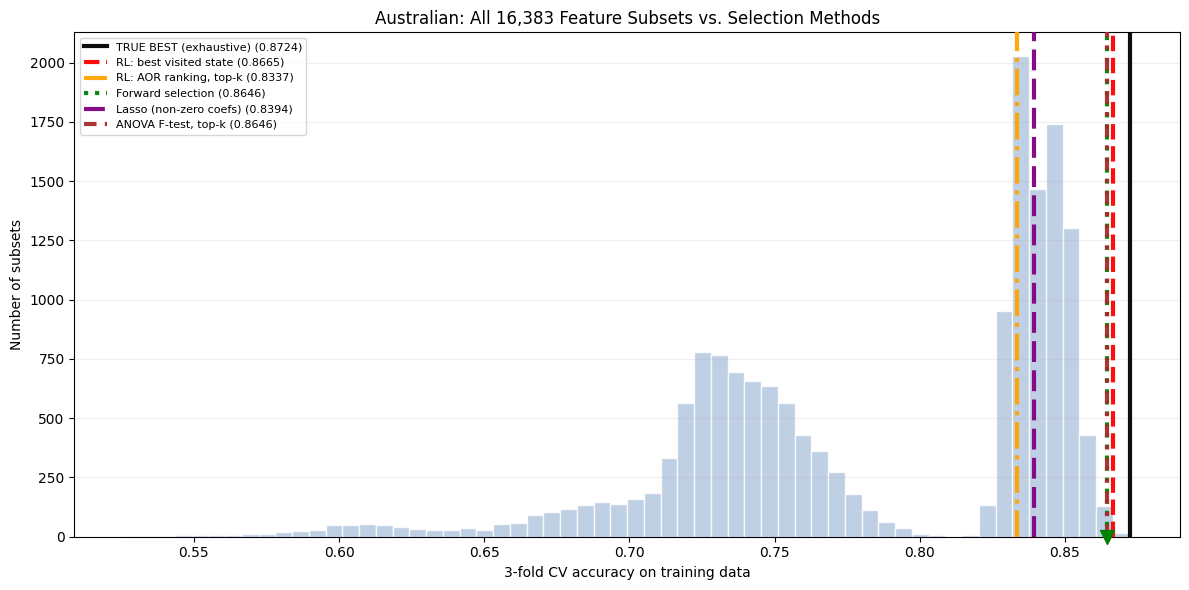


Saved: australian_groundtruth_table.csv, results_australian_groundtruth.json, australian_groundtruth.png


In [ ]:
"""
Replication of: "Feature Selection using Reinforcement Learning"
(Rasoul, Adewole, Akakpo - 2021, arXiv:2101.09460)

GROUND-TRUTH CHECK on the Australian Credit Approval dataset
-------------------------------------------------------------
14 features  ->  only 2^14 = 16,384 subsets (16,383 non-empty), so we can search ALL of them.
Steps:
  1. Exhaustively score every subset  -> find the TRUE best subset.
  2. Train the RL agent (TD(0) + AOR, as in the paper) and test whether it reaches that subset.
  3. Compare with Forward Selection, Lasso and ANOVA.

Changes vs. the earlier Australian script (as required: different seeds and splits):
  - RNG_SEED  42   -> 2026
  - TEST_SIZE 0.30 -> 0.25   (a different train/test split)

File format: /content/australian.dat  (whitespace separated, no header, last column = 0/1 label)

NOTE: the exhaustive search trains ~16k x 3 SVMs.  It uses all CPU cores (joblib) and takes
a few minutes in Colab.  Every score is cached, so everything after it is almost instant.
"""

import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.svm import SVC
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score

# ---------------------------------------------------------------
# 0. Settings
# ---------------------------------------------------------------
DATA_PATH = "/content/australian.dat"
RNG_SEED = 2026          # different from the earlier run (42)
TEST_SIZE = 0.25         # different from the earlier run (0.30)
N_EPISODES = 120
ALPHA, GAMMA, EPSILON = 0.3, 0.9, 0.4
N_RL_RUNS = 20           # repeat the RL agent with different seeds to see how often it hits the optimum

random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

# ---------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------
df = pd.read_csv(DATA_PATH, header=None, sep=r"\s+")
X = df.iloc[:, :-1].values.astype(float)
y = df.iloc[:, -1].values.astype(int)
n_features = X.shape[1]
print(f"Loaded Australian dataset: {X.shape[0]} samples, {n_features} features")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RNG_SEED
)
print(f"Train: {len(y_train)}  Test: {len(y_test)}  (seed={RNG_SEED}, test_size={TEST_SIZE})")

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RNG_SEED)

# ---------------------------------------------------------------
# 2. Subset scorer = the SAME objective the RL agent uses as its reward:
#    3-fold CV accuracy of an RBF-SVM on the TRAIN data. Cached.
# ---------------------------------------------------------------
_eval_cache = {}

def state_accuracy(feature_set):
    if len(feature_set) == 0:
        return 0.5
    key = frozenset(feature_set)
    if key not in _eval_cache:
        cols = sorted(key)
        _eval_cache[key] = cross_val_score(
            SVC(kernel="rbf", C=1.0, gamma="scale"), X_train_s[:, cols], y_train, cv=cv
        ).mean()
    return _eval_cache[key]

# ---------------------------------------------------------------
# 3. GROUND TRUTH: exhaustive search over all 2^14 - 1 non-empty subsets
# ---------------------------------------------------------------
def score_mask(mask):
    cols = [j for j in range(n_features) if (mask >> j) & 1]
    acc = cross_val_score(SVC(kernel="rbf", C=1.0, gamma="scale"),
                          X_train_s[:, cols], y_train, cv=cv).mean()
    return mask, acc

print(f"\nExhaustive search over {2 ** n_features - 1:,} subsets ... (a few minutes)")
t0 = time.time()
out = Parallel(n_jobs=-1, batch_size=64)(delayed(score_mask)(m) for m in range(1, 2 ** n_features))
for mask, acc in out:
    _eval_cache[frozenset(j for j in range(n_features) if (mask >> j) & 1)] = acc
print(f"Done in {time.time() - t0:.0f}s")

all_scores = np.array([a for _, a in out])
best_score = all_scores.max()
tol = 1e-12
tied = [s for s, a in _eval_cache.items() if abs(a - best_score) < tol]
true_best = sorted(tied, key=lambda s: (len(s), sorted(s)))[0]   # tie-break: fewest features, then lowest index
print(f"\nTRUE best train-CV accuracy: {best_score:.4f}")
print(f"Number of subsets that tie for the best score: {len(tied)}")
print(f"True best subset (fewest features among ties): {sorted(true_best)}  (k={len(true_best)})")

def rank_of(score):
    """1 = best. Rank = 1 + number of subsets with strictly higher CV accuracy."""
    return int((all_scores > score + tol).sum()) + 1

def test_acc(cols):
    cols = sorted(cols)
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
    clf.fit(X_train[:, cols], y_train)
    return accuracy_score(y_test, clf.predict(X_test[:, cols]))

def best_topk(order):
    """Choose k for a ranked feature list using TRAIN CV accuracy only (ties -> smaller k)."""
    best = max(range(1, n_features + 1), key=lambda k: (state_accuracy(frozenset(order[:k])), -k))
    return frozenset(int(c) for c in order[:best])

# ---------------------------------------------------------------
# 4. RL agent (TD(0) + AOR, exactly as in the paper / earlier script)
#    Because every subset is cached, training is now instant.
# ---------------------------------------------------------------
def run_rl(seed):
    rng = random.Random(seed)
    V, visited = {}, set()
    AOR = np.zeros(n_features)
    cnt = np.zeros(n_features, dtype=int)
    seen_states = set()
    pool = list(range(n_features))
    for _ in range(N_EPISODES):
        state = frozenset({rng.choice(pool)})
        cnt[list(state)] += 1
        seen_states.add(state)
        while len(state) < n_features:
            avail = [f for f in pool if f not in state]
            if state not in visited:
                a = rng.choice(avail)                         # random phase (unseen state)
            elif rng.random() < EPSILON:
                a = rng.choice(avail)                         # explore
            else:
                a = max(avail, key=lambda f: AOR[f])          # exploit best AOR
            visited.add(state)
            nxt = frozenset(state | {a})
            r = state_accuracy(nxt) - state_accuracy(state)
            v, v2 = V.get(state, 0.0), V.get(nxt, 0.0)
            V[state] = v + ALPHA * (r + GAMMA * v2 - v)       # TD(0)
            cnt[a] += 1
            AOR[a] = ((cnt[a] - 1) * AOR[a] + v2) / cnt[a]    # AOR update
            state = nxt
            seen_states.add(state)
    ranking = np.argsort(-AOR)
    # (a) best subset the agent actually VISITED (by train-CV accuracy; ties -> fewest features)
    best_visited = sorted(seen_states, key=lambda s: (-state_accuracy(s), len(s), sorted(s)))[0]
    # (b) top-k of the agent's AOR ranking, k chosen by train-CV accuracy
    topk = best_topk(ranking)
    return ranking, best_visited, topk, len(seen_states)

ranking, rl_visited, rl_topk, n_seen = run_rl(RNG_SEED)
print(f"\nRL agent visited {n_seen:,} of {2 ** n_features:,} possible states in {N_EPISODES} episodes")

# ---------------------------------------------------------------
# 5. Baselines: Forward selection, Lasso, ANOVA  (same objective, same train data)
# ---------------------------------------------------------------
# Forward selection: greedily add the feature that raises train-CV accuracy most; keep best point on the path
sel, path = [], []
for _ in range(n_features):
    f_best = max((f for f in range(n_features) if f not in sel),
                 key=lambda f: state_accuracy(frozenset(sel + [f])))
    sel.append(f_best)
    path.append(frozenset(sel))
fwd = max(path, key=lambda s: (state_accuracy(s), -len(s)))

# Lasso: L1 regression on the 0/1 label; keep features with non-zero coefficient
lasso = LassoCV(cv=5, random_state=RNG_SEED).fit(X_train_s, y_train)
lasso_set = frozenset(int(j) for j in np.flatnonzero(np.abs(lasso.coef_) > 1e-8))
if not lasso_set:
    lasso_set = frozenset({int(np.argmax(np.abs(lasso.coef_)))})

# ANOVA F-test: rank by F-score, choose k by train-CV accuracy
f_scores, _ = f_classif(X_train, y_train)
anova = best_topk(np.argsort(-np.nan_to_num(f_scores)))

# ---------------------------------------------------------------
# 6. Results table
# ---------------------------------------------------------------
methods = {
    "TRUE BEST (exhaustive)":        true_best,
    "RL: best visited state":        rl_visited,
    "RL: AOR ranking, top-k":        rl_topk,
    "Forward selection":             fwd,
    "Lasso (non-zero coefs)":        lasso_set,
    "ANOVA F-test, top-k":           anova,
    "All 14 features":               frozenset(range(n_features)),
}
rows = []
for name, s in methods.items():
    sc = state_accuracy(s)
    rows.append({
        "Method": name,
        "k": len(s),
        "Features": sorted(s),
        "Train-CV acc": round(sc, 4),
        "Gap to optimum": round(best_score - sc, 4),
        "Rank (of 16,383)": rank_of(sc),
        "Test acc": round(test_acc(s), 4),
        "Same subset as optimum?": "YES" if s == true_best else ("tied-best score" if abs(sc - best_score) < tol else "no"),
    })
res = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_colwidth", 60)
print("\n" + "=" * 100)
print("GROUND-TRUTH COMPARISON (objective = 3-fold CV accuracy on training data; Test acc = held-out)")
print("=" * 100)
print(res.to_string(index=False))

# ---------------------------------------------------------------
# 7. Does the RL agent reach the optimum?  Repeat with different agent seeds.
# ---------------------------------------------------------------
hits = {"best visited": [0, 0], "AOR top-k": [0, 0]}   # [exact same subset, same best score]
gaps = {"best visited": [], "AOR top-k": []}
for sd in range(N_RL_RUNS):
    _, bv, tk, _ = run_rl(1000 + sd)
    for key, s in [("best visited", bv), ("AOR top-k", tk)]:
        sc = state_accuracy(s)
        hits[key][0] += int(s == true_best)
        hits[key][1] += int(abs(sc - best_score) < tol)
        gaps[key].append(best_score - sc)
print(f"\nRL reach-rate over {N_RL_RUNS} independent agent runs ({N_EPISODES} episodes each):")
for key in hits:
    print(f"  {key:13s}: exact optimum subset {hits[key][0]}/{N_RL_RUNS}  |  "
          f"optimum score (incl. ties) {hits[key][1]}/{N_RL_RUNS}  |  "
          f"mean gap {np.mean(gaps[key]):.4f}, worst gap {np.max(gaps[key]):.4f}")


# ---------------------------------------------------------------
# 8. Plot: where does each method land among ALL 16,383 subsets?
# ---------------------------------------------------------------
plt.figure(figsize=(12, 6))

plt.hist(
    all_scores,
    bins=60,
    color="lightsteelblue",
    edgecolor="white",
    alpha=0.8
)

styles = [
    ("TRUE BEST (exhaustive)", "black", "-"),
    ("RL: best visited state", "red", "--"),
    ("RL: AOR ranking, top-k", "orange", "-."),
    ("Forward selection", "green", ":"),
    ("Lasso (non-zero coefs)", "purple", (0, (5, 2))),
    ("ANOVA F-test, top-k", "brown", (0, (3, 2, 1, 2))),
]

# Plot the methods with thicker lines
for name, col, ls in styles:
    score = state_accuracy(methods[name])

    plt.axvline(
        x=score,
        color=col,
        linestyle=ls,
        linewidth=3,
        alpha=0.95,
        label=f"{name} ({score:.4f})",
        zorder=5
    )

# Print each method's exact CV score for debugging
print("\nScores used in the graph:")
for name, _, _ in styles:
    print(f"{name:30s}: {state_accuracy(methods[name]):.6f}")

# Highlight Forward Selection's position with a marker
fwd_score = state_accuracy(methods["Forward selection"])
plt.scatter(
    [fwd_score],
    [0],
    color="green",
    marker="v",
    s=100,
    zorder=10,
    clip_on=False
)

plt.xlabel("3-fold CV accuracy on training data")
plt.ylabel("Number of subsets")
plt.title("Australian: All 16,383 Feature Subsets vs. Selection Methods")
plt.legend(fontsize=8, loc="best")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig("australian_groundtruth.png", dpi=160, bbox_inches="tight")
plt.show()


# ---------------------------------------------------------------
# 9. Save
# ---------------------------------------------------------------
res.to_csv("australian_groundtruth_table.csv", index=False)
with open("results_australian_groundtruth.json", "w") as f:
    json.dump({
        "seed": RNG_SEED, "test_size": TEST_SIZE, "n_subsets": 2 ** n_features - 1,
        "true_best_subset": sorted(true_best), "true_best_cv_acc": float(best_score),
        "n_tied_for_best": len(tied), "rl_reach": {k: {"exact": v[0], "score": v[1], "runs": N_RL_RUNS} for k, v in hits.items()},
        "table": res.to_dict(orient="records"),
    }, f, indent=2, default=str)
print("\nSaved: australian_groundtruth_table.csv, results_australian_groundtruth.json, australian_groundtruth.png")